# Glucemia, índice de masa corporal y edad como predictores de diabetes tipo 2 en mujeres pima: análisis de una cohorte de datos abiertos
Cuaderno de análisis (ejecutado). Datos: 768 mujeres pima (NIDDK / UCI).

In [1]:
import pandas as pd, numpy as np
from scipy import stats
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
%matplotlib inline
df = pd.read_csv(r'diabetes_pima.csv')
print(df.shape)

(768, 9)


## 1. Datos perdidos
Los ceros en glucosa, presión, pliegue, insulina e IMC se recodifican como perdidos.

In [2]:
for c in ['glucosa','presion_diastolica','pliegue_triceps','insulina','imc']:
    df[c] = df[c].replace(0, np.nan)
print(df.isna().sum())

embarazos               0
glucosa                 5
presion_diastolica     35
pliegue_triceps       227
insulina              374
imc                    11
pedigri_diabetes        0
edad                    0
diabetes                0
dtype: int64


## 2. Descriptivos por grupo (Tabla 1)

In [3]:
vars_ = ['edad','embarazos','glucosa','presion_diastolica','imc','pedigri_diabetes']
filas = []
for v in vars_:
    a = df.loc[df.diabetes==1, v].dropna(); b = df.loc[df.diabetes==0, v].dropna()
    p = stats.mannwhitneyu(a, b).pvalue
    filas.append([v, f'{b.median():.1f} [{b.quantile(.25):.1f}-{b.quantile(.75):.1f}]', f'{a.median():.1f} [{a.quantile(.25):.1f}-{a.quantile(.75):.1f}]', f'{p:.3g}'])
tabla1 = pd.DataFrame(filas, columns=['Variable','Sin diabetes (n=500)','Con diabetes (n=268)','p (Mann-Whitney)'])
print(df.diabetes.value_counts())
tabla1

diabetes
0    500
1    268
Name: count, dtype: int64


,Variable,Sin diabetes (n=500),Con diabetes (n=268),p (Mann-Whitney)
0,edad,27.0 [23.0-37.0],36.0 [28.0-44.0],1.14e-17
1,embarazos,2.0 [1.0-5.0],4.0 [1.8-8.0],3.75e-08
2,glucosa,107.0 [93.0-125.0],140.0 [119.0-167.0],1.31e-40
3,presion_diastolica,70.0 [62.0-78.0],74.5 [68.0-84.0],1.63e-06
4,imc,30.1 [25.6-35.3],34.3 [30.9-38.9],1.82e-17
5,pedigri_diabetes,0.3 [0.2-0.6],0.4 [0.3-0.7],1.2e-06


## 3. Figura 1: glucosa e IMC según diabetes

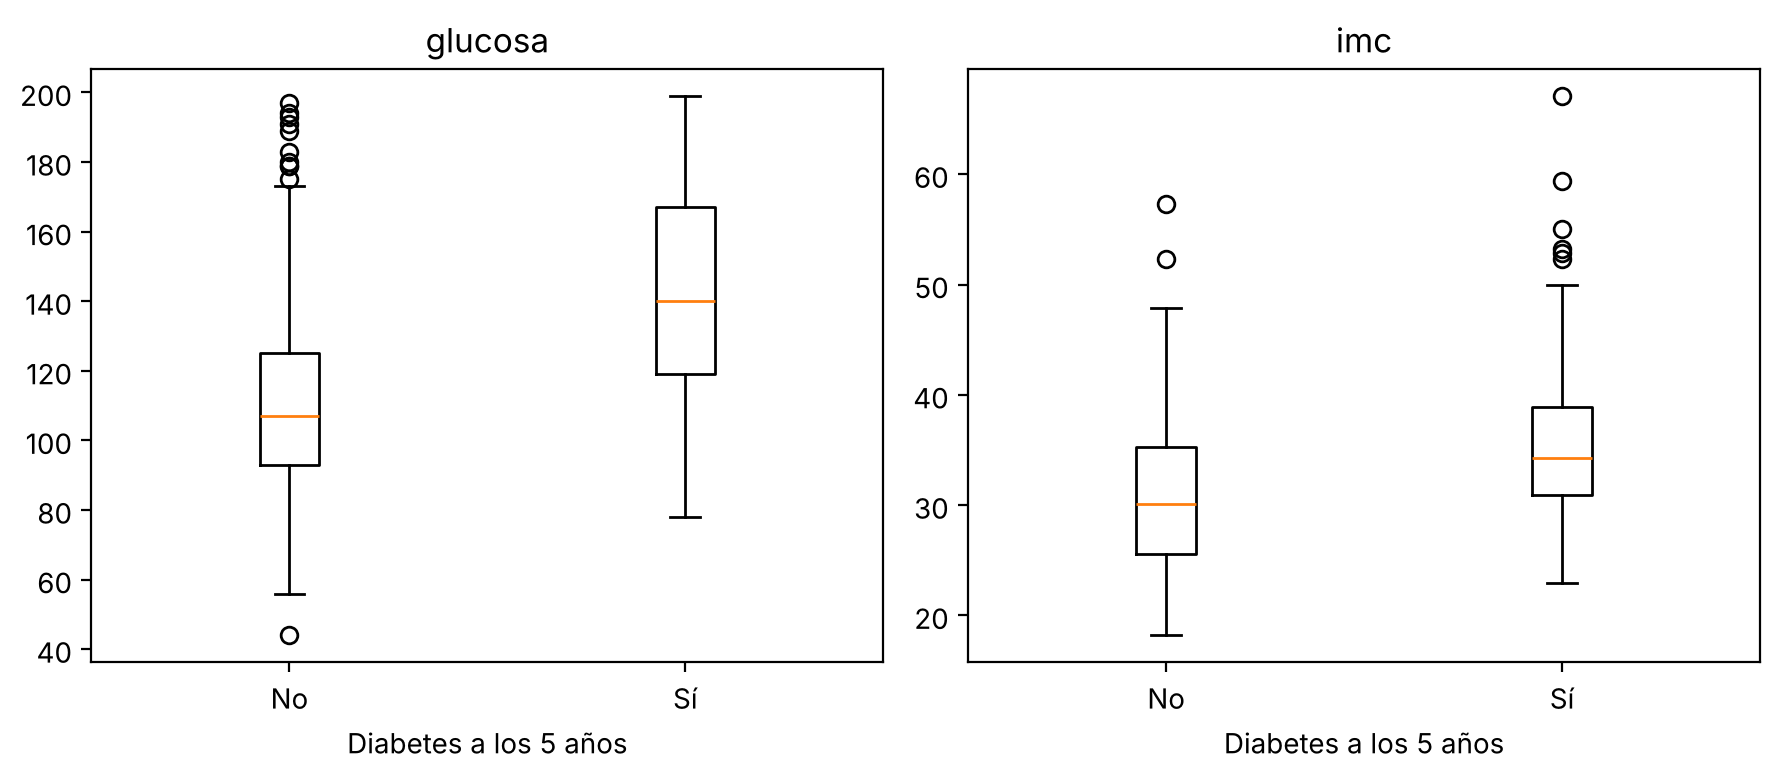

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for i, v in enumerate(['glucosa','imc']):
    ax[i].boxplot([df.loc[df.diabetes==0, v].dropna(), df.loc[df.diabetes==1, v].dropna()], tick_labels=['No','Sí'])
    ax[i].set_title(v); ax[i].set_xlabel('Diabetes a los 5 años')
plt.tight_layout(); plt.savefig('figura1.png', dpi=120); plt.show()

## 4. Regresión logística multivariable (Tabla 2)

In [5]:
d = df.dropna(subset=['glucosa','imc','edad','pedigri_diabetes','embarazos','presion_diastolica']).copy()
d['glucosa10'] = d.glucosa/10; d['edad10'] = d.edad/10
m = smf.logit('diabetes ~ glucosa10 + imc + edad10 + pedigri_diabetes + embarazos + presion_diastolica', data=d).fit(disp=0)
or_ = pd.DataFrame({'OR': np.exp(m.params), 'IC95_inf': np.exp(m.conf_int()[0]), 'IC95_sup': np.exp(m.conf_int()[1]), 'p': m.pvalues}).round(3)
print('n analizado =', int(m.nobs))
or_

n analizado = 724


,OR,IC95_inf,IC95_sup,p
Intercept,0.000,0.000,0.001,0.000
glucosa10,1.422,1.325,1.526,0.000
imc,1.095,1.062,1.130,0.000
edad10,1.185,0.977,1.436,0.085
pedigri_diabetes,2.613,1.433,4.764,0.002
embarazos,1.125,1.054,1.201,0.000
presion_diastolica,0.991,0.975,1.008,0.301


## 5. Capacidad discriminativa

In [6]:
from sklearn.metrics import roc_auc_score
auc = roc_auc_score(d.diabetes, m.predict(d))
print(f'AUC = {auc:.3f}')
print(f'Pseudo-R2 de McFadden = {m.prsquared:.3f}')

AUC = 0.843
Pseudo-R2 de McFadden = 0.278
